In [1]:
import os
os.chdir("..")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
 classification_report, roc_auc_score)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from src.data import add_features, clean_data, load_data
from src.preprocessing import build_preprocessor

In [3]:
df = add_features(clean_data(load_data()))
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, stratify=y, random_state=42
)

In [10]:
#Premiere foret, paramètres par défaut + class_weight ---
rf = Pipeline([
 ("prep", build_preprocessor(X_train)),
 ("model", RandomForestClassifier(
 n_estimators=500, class_weight="balanced",
 oob_score=True, n_jobs=-1, random_state=42)),
])
rf.fit(X_train, y_train)
print("OOB score :", round(rf["model"].oob_score_, 3)) # estimation gratuite de la perf

OOB score : 0.78


In [11]:
# Comparer à l'arbre seul avec la même validation croisée
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="roc_auc")
print("RF AUC CV :", scores.mean().round(3), "+/-", scores.std().round(3))


RF AUC CV : 0.83 +/- 0.011


In [12]:
#Évaluation sur le test ---
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print("ROC AUC test :", round(roc_auc_score(y_test, y_proba), 3))

              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1035
           1       0.55      0.63      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409

ROC AUC test : 0.827


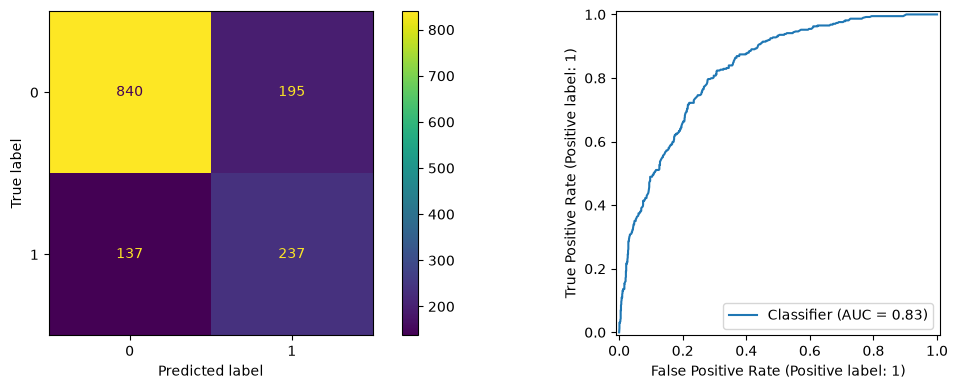

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
plt.tight_layout(); plt.show()

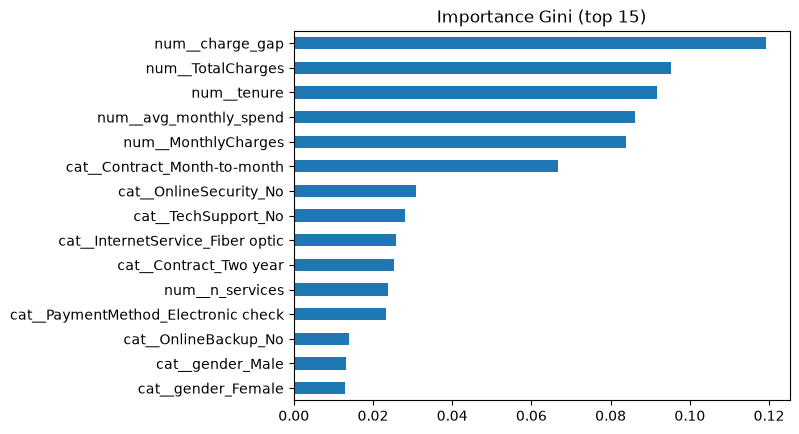

In [14]:
# Importance des variables : deux méthodes à comparer ---
# a) importance interne (Gini) : rapide mais biaisée vers les variables à haute cardinalité
names = rf["prep"].get_feature_names_out()
imp_gini = pd.Series(rf["model"].feature_importances_, index=names)
imp_gini.nlargest(15).sort_values().plot.barh(title="Importance Gini (top 15)")
plt.show()

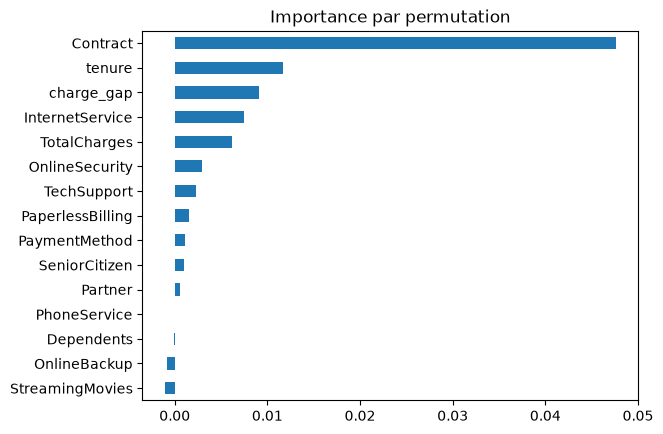

In [15]:
# importance par permutation : plus fiable, calculée sur les colonnes d'origine
perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
 scoring="roc_auc", random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_test.columns)
imp_perm.nlargest(15).sort_values().plot.barh(title="Importance par permutation")
plt.show()
